# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [1]:
# Напишите ваш код здесь
import pandas as pd

# Пример загрузки или анализа данных
# df = pd.read_csv('telecom_churn.csv')
# print(df.nunique())

In [2]:
import numpy as np
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

df = pd.read_csv('Orange_Telecom_Churn_Data.csv')
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns, missing values: {df.isna().sum().sum()}")

dropped_cols = ['state', 'area_code', 'phone_number']
categorical_cols = ['intl_plan', 'voice_mail_plan', 'churned']

cardinality = pd.DataFrame({
    'unique_values': df[dropped_cols + categorical_cols].nunique(),
    'status': ['dropped'] * len(dropped_cols) + ['kept'] * len(categorical_cols),
})
display(cardinality)

data = df.drop(columns=dropped_cols)
for col in categorical_cols:
    data[col] = LabelBinarizer().fit_transform(data[col]).ravel()

X_data = data.drop(columns='churned')
y_data = data['churned']
print(f"Model input: {X_data.shape[1]} features, churn rate {y_data.mean():.2%}")

phone_one_hot = pd.get_dummies(df['phone_number']).to_numpy(dtype=np.int8)
n_columns_with_phone = X_data.shape[1] + phone_one_hot.shape[1]
print(f"With phone one-hot: {X_data.shape[1]} -> {n_columns_with_phone} columns, float64 matrix "
      f"{len(df) * X_data.shape[1] * 8 / 1e6:.1f} MB -> {len(df) * n_columns_with_phone * 8 / 1e6:.1f} MB")
print(f"Squared distance added by phone one-hot between ANY two customers: {np.sum((phone_one_hot[0] - phone_one_hot[1]) ** 2)}")

states = df['state'].to_numpy()
state_one_hot = pd.get_dummies(df['state']).to_numpy(dtype=float)
for name, features in [('17 numeric features', X_data.to_numpy()), ('+ state one-hot', np.hstack([X_data, state_one_hot]))]:
    scaled = MinMaxScaler().fit_transform(features)
    _, neighbours = KNeighborsClassifier(n_neighbors=2).fit(scaled, y_data).kneighbors(scaled)
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=9))
    scores = cross_validate(model, features, y_data, cv=cv, scoring=['accuracy', 'f1'])
    print(f"{name}: nearest neighbour from the same state {np.mean(states[neighbours[:, 1]] == states):.1%}, "
          f"CV accuracy {scores['test_accuracy'].mean():.4f}, CV F1 {scores['test_f1'].mean():.4f}")

Dataset: 5000 rows, 21 columns, missing values: 0


,unique_values,status
state,51,dropped
area_code,3,dropped
phone_number,5000,dropped
intl_plan,2,kept
voice_mail_plan,2,kept
churned,2,kept


Model input: 17 features, churn rate 14.14%
With phone one-hot: 17 -> 5017 columns, float64 matrix 0.7 MB -> 200.7 MB
Squared distance added by phone one-hot between ANY two customers: 2


17 numeric features: nearest neighbour from the same state 1.8%, CV accuracy 0.9012, CV F1 0.5012
+ state one-hot: nearest neighbour from the same state 100.0%, CV accuracy 0.8628, CV F1 0.0949


Вывод: я посчитал кардинальность категориальных колонок: у phone_number 5000 уникальных значений на 5000 клиентов, у state 51, у area_code 3, а у intl_plan, voice_mail_plan и churned по 2 значения. Номер телефона уникален у каждого клиента, поэтому это идентификатор, а не признак, и после OneHotEncoder таблица выросла бы с 17 до 5017 столбцов, а память с 0.7 до 200.7 МБ. С математической точки зрения one-hot векторы телефонов у любых двух клиентов отличаются ровно в двух позициях, поэтому к квадрату расстояния каждой пары добавляется одна и та же двойка, и признак ничего не говорит о сходстве клиентов, а только увеличивает размерность. Для state я проверил это на практике: после one-hot ближайший сосед в 100% случаев оказывается из того же штата (без него 1.8%), потому что разница в штате добавляет к квадрату расстояния 2, а это больше обычных различий по 17 признакам. Из-за этого F1 на кросс-валидации упал с 0.501 до 0.095, а accuracy с 0.901 до 0.863, то есть модель ищет соседей только среди примерно 98 клиентов своего штата и переобучается. Поэтому колонки state, area_code и phone_number я удалил, а intl_plan, voice_mail_plan и churned закодировал в 0/1 через LabelBinarizer. Данные я читал из Orange_Telecom_Churn_Data.csv, который восстановил из приложенного xlsx, так как Excel превратил часть дробных чисел в даты.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
# Напишите ваш код для сравнения скейлеров здесь

In [4]:
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline

feature_ranges = pd.DataFrame({'account_length': [1, 250], 'total_day_charge': [0, 100]})
clients = pd.DataFrame({'account_length': [50, 200], 'total_day_charge': [10, 90]}, index=['client_A', 'client_B'])
display(clients)


def describe_distance(title, a, b):
    squared_diff = (np.asarray(a, dtype=float) - np.asarray(b, dtype=float)) ** 2
    shares = squared_diff / squared_diff.sum()
    print(f"{title}: distance = {np.sqrt(squared_diff.sum()):.3f}, "
          f"account_length share = {shares[0]:.1%}, total_day_charge share = {shares[1]:.1%}")


clients_scaled = MinMaxScaler().fit(feature_ranges).transform(clients)
describe_distance("Without scaling", clients.iloc[0], clients.iloc[1])
describe_distance("With MinMaxScaler", clients_scaled[0], clients_scaled[1])

with_outlier = pd.DataFrame({
    'account_length': [60, 80, 100, 120, 140, 160],
    'total_day_charge': [20, 25, 30, 35, 40, 1000],
})
scaled_charge = {}
for name, scaler in [('MinMaxScaler', MinMaxScaler()), ('StandardScaler', StandardScaler()), ('RobustScaler', RobustScaler())]:
    scaled = scaler.fit_transform(with_outlier)
    scaled_charge[name] = scaled[:, 1]
    describe_distance(f"{name}, normal clients 1 and 5", scaled[0], scaled[4])
display(pd.DataFrame(scaled_charge, index=with_outlier['total_day_charge']).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.25, stratify=y_data, random_state=RANDOM_STATE
)
for name, scaler in [('no scaling', 'passthrough'), ('MinMaxScaler', MinMaxScaler()), ('StandardScaler', StandardScaler())]:
    model = Pipeline([('scaler', scaler), ('knn', KNeighborsClassifier())])
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    print(f"Churn data, KNN 5-fold CV accuracy with {name}: {scores.mean():.4f} +/- {scores.std():.4f}")

scaler = MinMaxScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

,account_length,total_day_charge
client_A,50,10
client_B,200,90


Without scaling: distance = 170.000, account_length share = 77.9%, total_day_charge share = 22.1%
With MinMaxScaler: distance = 1.001, account_length share = 36.2%, total_day_charge share = 63.8%
MinMaxScaler, normal clients 1 and 5: distance = 0.800, account_length share = 99.9%, total_day_charge share = 0.1%
StandardScaler, normal clients 1 and 5: distance = 2.343, account_length share = 99.9%, total_day_charge share = 0.1%
RobustScaler, normal clients 1 and 5: distance = 2.263, account_length share = 50.0%, total_day_charge share = 50.0%


,MinMaxScaler,StandardScaler,RobustScaler
total_day_charge,,,
20,0.000,-0.475,-1.0
25,0.005,-0.461,-0.6
30,0.010,-0.447,-0.2
35,0.015,-0.433,0.2
40,0.020,-0.419,0.6
1000,1.000,2.236,77.4


Churn data, KNN 5-fold CV accuracy with no scaling: 0.8848 +/- 0.0043
Churn data, KNN 5-fold CV accuracy with MinMaxScaler: 0.9003 +/- 0.0093


Churn data, KNN 5-fold CV accuracy with StandardScaler: 0.8997 +/- 0.0079


Вывод: для двух клиентов (50 и 200 дней, 10 и 90 у.е.) расстояние без масштабирования равно 170, и 77.9% его квадрата даёт account_length, хотя по total_day_charge клиенты различаются сильнее (на 80% диапазона против 60%). После MinMaxScaler доли стали 36.2% и 63.8%, потому что каждый признак приводится к диапазону [0, 1]. Когда я добавил выброс 1000 в total_day_charge, MinMaxScaler сжал обычные значения в интервал от 0 до 0.02, а StandardScaler в интервал от -0.475 до -0.419, поэтому у двух обычных клиентов доля этого признака в расстоянии упала до 0.1% для обоих скейлеров. StandardScaler здесь не лучше MinMaxScaler, так как среднее и стандартное отклонение тоже сильно сдвигаются из-за одного выброса, а RobustScaler, который использует медиану и квартили, сохранил баланс 50% на 50%. На реальных данных кросс-валидация на обучающей выборке дала accuracy 0.8848 без масштабирования, 0.9003 с MinMaxScaler и 0.8997 со StandardScaler. Разница между двумя скейлерами меньше стандартного отклонения (0.0093 и 0.0079), поэтому, скорее всего, она случайная, а само масштабирование даёт примерно 1.5 п.п.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [5]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Создание синтетических данных
X = np.random.rand(100000, 10)
y = np.random.randint(0, 2, 100000)

# Измерение времени обучения без патча и с патчем

In [6]:
import timeit
from sklearnex import patch_sklearn, unpatch_sklearn

X_query = X[:2000]
REPEATS = 3


def time_knn(knn_class):
    model = knn_class(n_neighbors=5)
    fit_seconds = timeit.timeit(lambda: model.fit(X, y), number=REPEATS) / REPEATS
    predict_seconds = timeit.timeit(lambda: model.predict(X_query), number=REPEATS) / REPEATS
    return fit_seconds, predict_seconds


stock_fit, stock_predict = time_knn(KNeighborsClassifier)

patch_sklearn(verbose=False)
from sklearn.neighbors import KNeighborsClassifier as PatchedKNeighborsClassifier
intel_fit, intel_predict = time_knn(PatchedKNeighborsClassifier)
unpatch_sklearn()

print(f"Patched class comes from: {PatchedKNeighborsClassifier.__module__}")
print(f"fit on 100,000 rows    | stock: {stock_fit:.3f} s | Intel: {intel_fit:.3f} s | speed-up x{stock_fit / intel_fit:.1f}")
print(f"predict for 2,000 rows | stock: {stock_predict:.3f} s | Intel: {intel_predict:.3f} s | speed-up x{stock_predict / intel_predict:.1f}")

Patched class comes from: sklearnex.neighbors.knn_classification
fit on 100,000 rows    | stock: 0.180 s | Intel: 0.027 s | speed-up x6.6
predict for 2,000 rows | stock: 0.354 s | Intel: 0.015 s | speed-up x23.8


Вывод: я измерил время на синтетических данных из 100000 объектов: обучение без патча заняло 0.180 с, а с патчем Intel 0.027 с (быстрее в 6.6 раза), предсказание для 2000 объектов заняло 0.354 с против 0.015 с (быстрее в 23.8 раза). Intel Extension заменяет реализацию KNeighborsClassifier на библиотеку oneDAL, которая написана на C++, использует все ядра процессора и векторные инструкции (AVX2 на моём процессоре, на серверных процессорах AVX-512 обрабатывает сразу 8 чисел). Вероятно, сам алгоритм поиска при этом тот же: для 10 признаков используется KD-Tree, которое делит пространство по координатам и отбрасывает далёкие ветви без вычисления расстояний. Предсказание ускорилось сильнее обучения, потому что fit у KNN только строит дерево, а основная работа, поиск соседей, происходит в predict. Надо учитывать, что время зависит от загрузки компьютера, поэтому при повторном запуске числа будут немного другими.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [7]:
def minkowski_distance(x, y, p):
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

# Протестируйте функцию и постройте границы принятия решений

p =   1: distance = 7.0000
p =   2: distance = 5.0000
p =   3: distance = 4.4979
p =  10: distance = 4.0220
p = 100: distance = 4.0000
Chebyshev (p -> inf): distance = 4.0000
2D churn data ['total_day_minutes', 'total_eve_minutes']: train 3500, test 1500, churn rate 14.14%


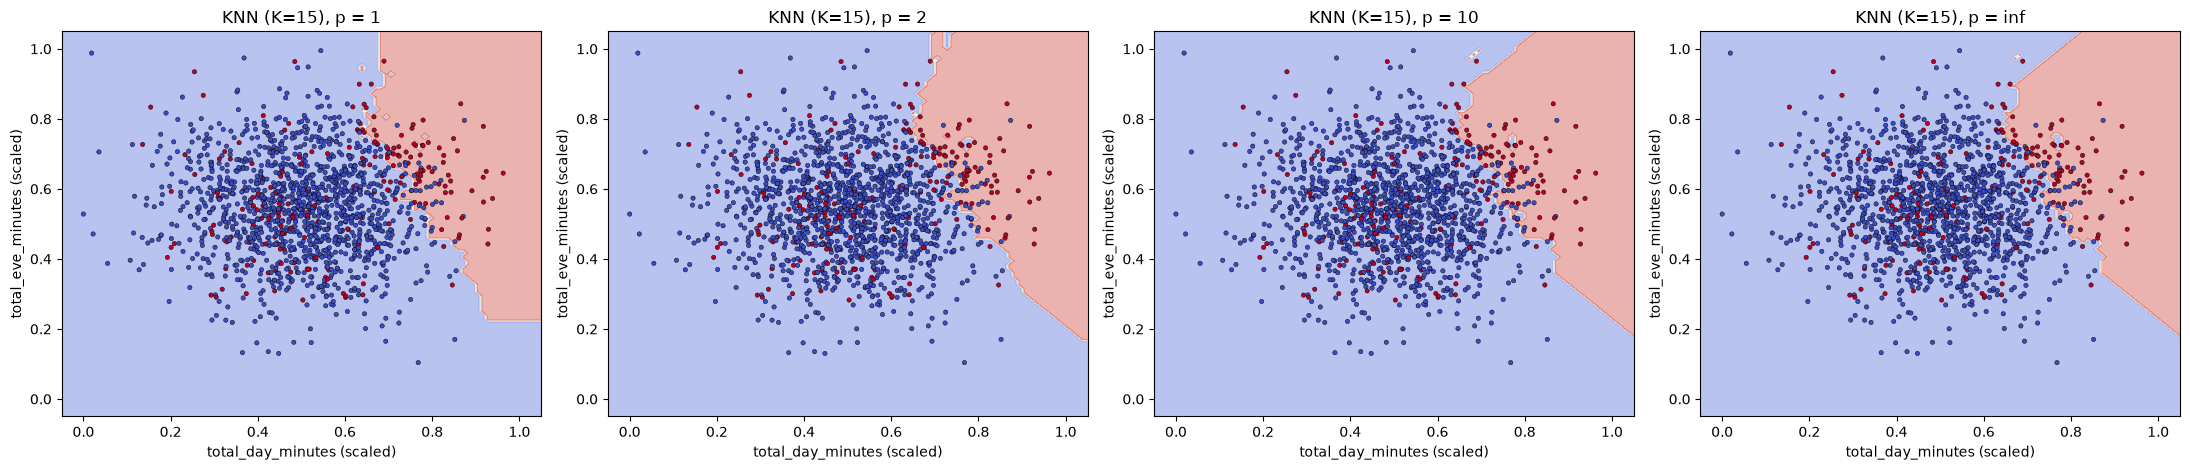

,test_accuracy,plane_differs_from_p2
p,,
1.0,0.883,0.010
1.5,0.881,0.004
2.0,0.879,0.000
3.0,0.880,0.006
5.0,0.880,0.010
10.0,0.879,0.013
50.0,0.881,0.014
inf,0.881,0.014


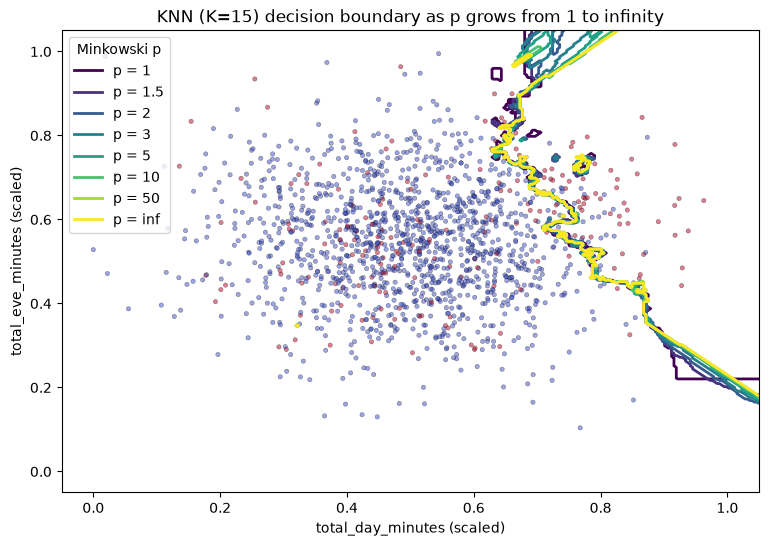

In [8]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

a = np.array([0.0, 0.0])
b = np.array([3.0, 4.0])
for p in [1, 2, 3, 10, 100]:
    print(f"p = {p:>3}: distance = {minkowski_distance(a, b, p):.4f}")
print(f"Chebyshev (p -> inf): distance = {np.max(np.abs(a - b)):.4f}")

features_2d = ['total_day_minutes', 'total_eve_minutes']
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_data[features_2d], y_data, test_size=0.3, stratify=y_data, random_state=RANDOM_STATE
)
scaler_2d = MinMaxScaler().fit(X_2d_train)
X_2d_train, X_2d_test = scaler_2d.transform(X_2d_train), scaler_2d.transform(X_2d_test)
print(f"2D churn data {features_2d}: train {len(X_2d_train)}, test {len(X_2d_test)}, churn rate {y_2d_train.mean():.2%}")

p_values = [1, 1.5, 2, 3, 5, 10, 50, np.inf]
models_2d = {
    p: KNeighborsClassifier(n_neighbors=15, **({'metric': 'chebyshev'} if p == np.inf else {'p': p})).fit(X_2d_train, y_2d_train)
    for p in p_values
}

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, p in zip(axes, [1, 2, 10, np.inf]):
    DecisionBoundaryDisplay.from_estimator(models_2d[p], X_2d_train, response_method='predict', eps=0.05,
                                           cmap='coolwarm', alpha=0.4, ax=ax)
    ax.scatter(X_2d_test[:, 0], X_2d_test[:, 1], c=y_2d_test, cmap='coolwarm', edgecolor='k', linewidth=0.3, s=10)
    ax.set_title(f'KNN (K=15), p = {p}')
    ax.set_xlabel('total_day_minutes (scaled)')
    ax.set_ylabel('total_eve_minutes (scaled)')
plt.tight_layout()
plt.show()

xx, yy = np.meshgrid(np.linspace(-0.05, 1.05, 300), np.linspace(-0.05, 1.05, 300))
grid = np.column_stack([xx.ravel(), yy.ravel()])
grid_predictions = {p: model.predict(grid) for p, model in models_2d.items()}
p_results = pd.DataFrame({
    'test_accuracy': [models_2d[p].score(X_2d_test, y_2d_test) for p in p_values],
    'plane_differs_from_p2': [np.mean(grid_predictions[p] != grid_predictions[2]) for p in p_values],
}, index=pd.Index(p_values, name='p'))
display(p_results.round(3))

colors = plt.cm.viridis(np.linspace(0, 1, len(p_values)))
plt.figure(figsize=(9, 6))
plt.scatter(X_2d_test[:, 0], X_2d_test[:, 1], c=y_2d_test, cmap='coolwarm', edgecolor='k', linewidth=0.3, s=10, alpha=0.5)
for color, p in zip(colors, p_values):
    plt.contour(xx, yy, grid_predictions[p].reshape(xx.shape), levels=[0.5], colors=[color], linewidths=2)
    plt.plot([], [], color=color, linewidth=2, label=f'p = {p}')
plt.legend(title='Minkowski p', loc='upper left')
plt.xlabel('total_day_minutes (scaled)')
plt.ylabel('total_eve_minutes (scaled)')
plt.title('KNN (K=15) decision boundary as p grows from 1 to infinity')
plt.show()

Вывод: я проверил свою функцию minkowski_distance на точках (0, 0) и (3, 4): при p = 1 расстояние 7, при p = 2 оно 5, при p = 10 уже 4.022, а при p = 100 равно 4.000, то есть совпадает с расстоянием Чебышева max(3, 4) = 4, потому что при большой степени самая большая разность подавляет остальные. Для границ решений я взял двумерный набор из данных churn (total_day_minutes и total_eve_minutes после MinMaxScaler, метка churned) и KNN с K = 15. На графиках зона ушедших клиентов находится справа вверху, и при p = 1 её граница идёт по вертикали и горизонтали, при p = 2 сверху почти вертикально, а снизу наклонно, а при p = 10 и p = ∞ и сверху, и снизу примерно под 45°. Так получается, потому что при p = 1 разности по осям складываются, а при p = ∞ учитывается только большая из них, и соседи по диагонали становятся такими же близкими, как соседи по прямой. По таблице ответ модели отличается от евклидова на 1.0% площади при p = 1 и на 1.4% при p = 50 и p = ∞, а на общем графике границы для p = 50 и p = ∞ практически совпадают. Accuracy на тестовой выборке при этом почти не меняется (от 0.879 до 0.883), так как граница сдвигается в основном там, где мало точек.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [9]:
# Эксперимент с K=1 на обучающей выборке

In [10]:
X_full_scaled = MinMaxScaler().fit_transform(X_data)

experiments = {
    'K=1, uniform': {'n_neighbors': 1},
    'K=3, uniform': {'n_neighbors': 3},
    'K=3, distance': {'n_neighbors': 3, 'weights': 'distance'},
}
rows = []
for name, params in experiments.items():
    full_model = KNeighborsClassifier(**params).fit(X_full_scaled, y_data)
    split_model = KNeighborsClassifier(**params).fit(X_train_scaled, y_train)
    rows.append({
        'model': name,
        'accuracy on its own training data': full_model.score(X_full_scaled, y_data),
        'accuracy on unseen test data': split_model.score(X_test_scaled, y_test),
    })
display(pd.DataFrame(rows).set_index('model').round(4))

distances, indices = KNeighborsClassifier(n_neighbors=1).fit(X_full_scaled, y_data).kneighbors(X_full_scaled[:3])
print(f"Nearest neighbour of customers 0, 1, 2: {indices.ravel()}, distances: {distances.ravel()}")

,accuracy on its own training data,accuracy on unseen test data
model,,
"K=1, uniform",1.0000,0.8736
"K=3, uniform",0.9422,0.8920
"K=3, distance",1.0000,0.8920


Nearest neighbour of customers 0, 1, 2: [0 1 2], distances: [0.00000000e+00 4.21468485e-08 2.98023224e-08]


Вывод: когда я обучил KNN на всех 5000 клиентах и проверил на них же, K = 1 и K = 3 с weights='distance' дали accuracy 1.0, а K = 3 с равными весами 0.9422. Это запоминание: KNN не строит модель, а хранит обучающую выборку, поэтому ближайший сосед точки x_i из обучающей выборки это она сама с расстоянием 0, что видно по выводу kneighbors (соседи клиентов 0, 1 и 2 это они же, расстояния 0 и около 4e-8 из-за погрешности вычислений). При K = 1 ответом становится собственная метка точки, а при weights='distance' вес соседа равен 1/d, и у самой точки он огромный, поэтому она перевешивает остальных соседей. При K = 3 с равными весами сама точка даёт только один голос из трёх, и два других соседа иногда её перевешивают. На тестовой выборке картина другая: K = 1 даёт только 0.8736, а K = 3 даёт 0.8920, значит, 100% на обучающих данных показывает переобучение, а не качество модели. Поэтому модель нужно оценивать только на данных, которых она не видела (задание 7).

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [11]:
class Custom:
    def __init__(self):
        pass
        
    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        
    def predict(self, X_test, k=3):
        # Реализуйте логику предсказания
        pass

In [12]:
class CustomKNN:
    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        squared_distances = (
            (X_test ** 2).sum(axis=1)[:, np.newaxis]
            + (self.X_train ** 2).sum(axis=1)
            - 2 * X_test @ self.X_train.T
        )
        distances = np.sqrt(np.maximum(squared_distances, 0))
        nearest = np.argpartition(distances, k - 1, axis=1)[:, :k]
        neighbour_labels = self.y_train[nearest]
        classes = np.unique(self.y_train)
        votes = (neighbour_labels[:, :, np.newaxis] == classes).sum(axis=1)
        return classes[votes.argmax(axis=1)]


X_small_train, y_small_train = X_train_scaled[:1000], y_train.to_numpy()[:1000]
X_small_test, y_small_test = X_test_scaled[:300], y_test.to_numpy()[:300]

custom_pred = CustomKNN().fit(X_small_train, y_small_train).predict(X_small_test, k=5)
sklearn_pred = KNeighborsClassifier(n_neighbors=5).fit(X_small_train, y_small_train).predict(X_small_test)

print(f"CustomKNN accuracy:   {np.mean(custom_pred == y_small_test):.4f}")
print(f"sklearn KNN accuracy: {np.mean(sklearn_pred == y_small_test):.4f}")
print(f"Same predictions as sklearn: {np.mean(custom_pred == sklearn_pred):.2%}")

CustomKNN accuracy:   0.8733
sklearn KNN accuracy: 0.8733
Same predictions as sklearn: 100.00%


Вывод: каркас Custom я оставил без изменений, а свой класс CustomKNN написал отдельно, потому что в условии требуется именно такое имя и методы fit(X, y) и predict(X_test, k). В predict я считаю евклидовы расстояния сразу для всех пар точек одной матричной операцией по формуле ‖a − b‖² = ‖a‖² + ‖b‖² − 2ab, поэтому циклов по точкам нет и NumPy работает быстро. Затем np.argpartition находит k ближайших соседей, а класс выбирается простым голосованием большинства. Я проверил класс на подмножестве churn (1000 клиентов для обучения и 300 для проверки) с k = 5: accuracy получилась 0.8733, как у KNeighborsClassifier, и предсказания совпали на 100%. Ограничение в том, что матрица расстояний хранится целиком, поэтому на очень больших данных, вероятно, не хватит памяти.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

In [13]:
from sklearn.model_selection import StratifiedKFold
# Напишите код кросс-валидации

,mean_accuracy,std_accuracy,validation_error
k,,,
1,0.8781,0.0097,0.1219
2,0.8891,0.0035,0.1109
3,0.9013,0.0058,0.0987
4,0.8933,0.0055,0.1067
5,0.9003,0.0093,0.0997
6,0.8925,0.0085,0.1075
7,0.8987,0.0102,0.1013
8,0.8931,0.0054,0.1069
9,0.9016,0.0088,0.0984


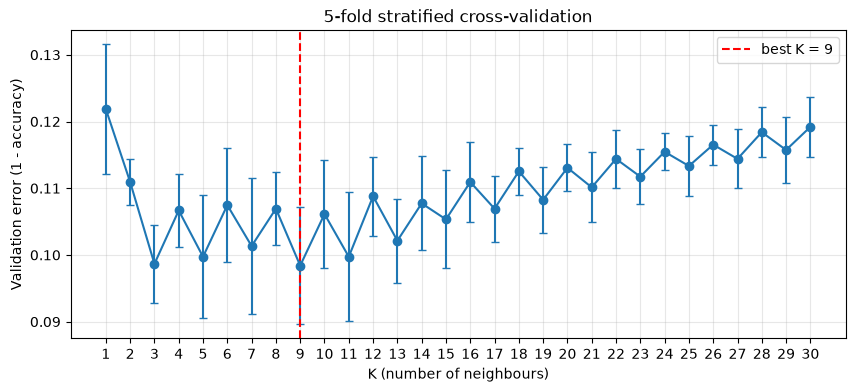

Best K = 9: mean accuracy 0.9016 +/- 0.0088


In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for k in range(1, 31):
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_rows.append({'k': k, 'mean_accuracy': scores.mean(), 'std_accuracy': scores.std()})

cv_results = pd.DataFrame(cv_rows).set_index('k')
cv_results['validation_error'] = 1 - cv_results['mean_accuracy']
best_k = cv_results['mean_accuracy'].idxmax()
display(cv_results.round(4))

plt.figure(figsize=(10, 4))
plt.errorbar(cv_results.index, cv_results['validation_error'], yerr=cv_results['std_accuracy'], marker='o', capsize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'best K = {best_k}')
plt.xlabel('K (number of neighbours)')
plt.ylabel('Validation error (1 - accuracy)')
plt.title('5-fold stratified cross-validation')
plt.xticks(range(1, 31))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = cv_results.loc[best_k]
print(f"Best K = {best_k}: mean accuracy {best['mean_accuracy']:.4f} +/- {best['std_accuracy']:.4f}")

Вывод: я провёл 5-Fold кросс-валидацию со StratifiedKFold (с перемешиванием и random_state = 42) на обучающей выборке для K от 1 до 30, а MinMaxScaler поставил внутрь pipeline, чтобы в каждом фолде он учился только на обучающей части. Лучшим оказалось K = 9 со средней accuracy 0.9016 ± 0.0088, то есть ошибка валидации 0.0984. При K = 1 ошибка самая большая (0.1219), потому что модель реагирует на каждый шумный объект, а при больших K ошибка снова растёт до 0.1192 при K = 30, так как голосуют слишком далёкие соседи и чаще побеждает большинство «не ушёл». Начиная с K = 4 чётные K хуже соседних нечётных, вероятно, из-за ничьих при голосовании. Нечётные K от 3 до 11 отличаются от лучшего не больше чем на 0.003, а это меньше стандартного отклонения, поэтому они почти равноценны.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
# Напишите код для расчета метрик

In [16]:
from sklearn.metrics import accuracy_score

y_pred = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_scaled, y_train).predict(X_test_scaled)

print(f"Test set: {(y_test == 0).sum()} stayed, {(y_test == 1).sum()} churned")
print(f"Accuracy of a 'model' that always says 'stayed': {accuracy_score(y_test, np.zeros_like(y_test)):.4f}")
print(f"Accuracy of KNN (K={best_k}):                       {accuracy_score(y_test, y_pred):.4f}")

display(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['actual: stayed', 'actual: churned'],
    columns=['predicted: stayed', 'predicted: churned'],
))
print(classification_report(y_test, y_pred, target_names=['stayed', 'churned'], digits=3))

Test set: 1073 stayed, 177 churned
Accuracy of a 'model' that always says 'stayed': 0.8584
Accuracy of KNN (K=9):                       0.8992


,predicted: stayed,predicted: churned
actual: stayed,1061,12
actual: churned,114,63


              precision    recall  f1-score   support

      stayed      0.903     0.989     0.944      1073
     churned      0.840     0.356     0.500       177

    accuracy                          0.899      1250
   macro avg      0.871     0.672     0.722      1250
weighted avg      0.894     0.899     0.881      1250



Вывод: в тестовой выборке 1073 клиента остались и только 177 ушли, поэтому модель, которая всем отвечает «остался», уже получает accuracy 0.8584. KNN с K = 9 (задание 7) дал accuracy 0.8992, то есть всего на 4 п.п. лучше, и по одной accuracy кажется, что модель работает хорошо. По матрице ошибок видно, что из 177 ушедших модель нашла только 63, а 114 пропустила, при этом ложных тревог всего 12. Для класса churned precision равна 0.840, recall 0.356 и F1 0.500, то есть когда модель говорит «уйдёт», она чаще всего права, но находит только треть ушедших. Accuracy вводит в заблуждение, потому что почти все правильные ответы в ней приходятся на большой класс оставшихся, поэтому для оттока нужно смотреть на recall и F1 меньшего класса.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [17]:
# Эксперимент с весами

In [18]:
datasets = {
    'churn, 17 features': (X_train_scaled, X_test_scaled, y_train.to_numpy(), y_test.to_numpy()),
    'churn, 2 features': (X_2d_train, X_2d_test, y_2d_train.to_numpy(), y_2d_test.to_numpy()),
}

noise_rows = []
for dataset_name, (X_tr, X_te, y_tr, y_te) in datasets.items():
    for noise in ['feature outliers', 'flipped labels']:
        for noise_share in [0.0, 0.1, 0.2, 0.3]:
            for seed in range(5):
                rng = np.random.default_rng(seed)
                noisy_idx = rng.choice(len(X_tr), size=int(noise_share * len(X_tr)), replace=False)
                X_noisy, y_noisy = X_tr.copy(), y_tr.copy()
                if noise == 'feature outliers':
                    X_noisy[noisy_idx] += rng.normal(0, 2 * X_tr.std(axis=0), size=(len(noisy_idx), X_tr.shape[1]))
                else:
                    y_noisy[noisy_idx] = 1 - y_noisy[noisy_idx]
                for weights in ['uniform', 'distance']:
                    model = KNeighborsClassifier(n_neighbors=15, weights=weights).fit(X_noisy, y_noisy)
                    noise_rows.append({'dataset': dataset_name, 'noise': noise, 'noisy_share': noise_share,
                                       'weights': weights, 'test_accuracy': model.score(X_te, y_te)})

noise_results = pd.DataFrame(noise_rows).pivot_table(
    index=['dataset', 'noise', 'noisy_share'], columns='weights', values='test_accuracy'
)[['uniform', 'distance']]
noise_results['uniform - distance'] = noise_results['uniform'] - noise_results['distance']
display(noise_results.round(4))

for dataset_name, (X_tr, X_te, y_tr, y_te) in datasets.items():
    distances, _ = KNeighborsClassifier(n_neighbors=15).fit(X_tr, y_tr).kneighbors(X_te)
    vote_weights = 1 / np.maximum(distances, 1e-9)
    nearest_share = np.mean(vote_weights[:, 0] / vote_weights.sum(axis=1))
    print(f"{dataset_name}: with weights='distance' the nearest neighbour gets {nearest_share:.1%} of the vote "
          f"(uniform: {1 / 15:.1%})")

weights                                          uniform  distance  \
dataset            noise            noisy_share                      
churn, 17 features feature outliers 0.0           0.8992    0.8992   
                                    0.1           0.8957    0.8957   
                                    0.2           0.8954    0.8957   
                                    0.3           0.8923    0.8922   
                   flipped labels   0.0           0.8992    0.8992   
                                    0.1           0.8950    0.8946   
                                    0.2           0.8848    0.8848   
                                    0.3           0.8376    0.8373   
churn, 2 features  feature outliers 0.0           0.8793    0.8813   
                                    0.1           0.8784    0.8777   
                                    0.2           0.8761    0.8751   
                                    0.3           0.8671    0.8653   
                   flipped labels   0.0           0.8793    0.8813   
                                    0.1           0.8792    0.8697   
                                    0.2           0.8580    0.8313   
                                    0.3           0.8065    0.7624   

weights                                          uniform - distance  
dataset            noise            noisy_share                      
churn, 17 features feature outliers 0.0                      0.0000  
                                    0.1                      0.0000  
                                    0.2                     -0.0003  
                                    0.3                      0.0002  
                   flipped labels   0.0                      0.0000  
                                    0.1                      0.0005  
                                    0.2                      0.0000  
                                    0.3                      0.0003  
churn, 2 features  feature outliers 0.0                     -0.0020  
                                    0.1                      0.0007  
                                    0.2                      0.0011  
                                    0.3                      0.0017  
                   flipped labels   0.0                     -0.0020  
                                    0.1                      0.0095  
                                    0.2                      0.0267  
                                    0.3                      0.0441

churn, 17 features: with weights='distance' the nearest neighbour gets 8.5% of the vote (uniform: 6.7%)
churn, 2 features: with weights='distance' the nearest neighbour gets 20.1% of the vote (uniform: 6.7%)


Вывод: я сравнил weights='uniform' и weights='distance' при K = 15, испортив 10, 20 и 30% обучающих точек двумя способами: сдвигал точки далеко в пространстве признаков (выбросы) или переворачивал их метки, и усреднил результат по 5 запускам. На полных данных churn (17 признаков) разницы почти нет, а на двумерном наборе из задания 4 при перевёрнутых метках distance хуже uniform на 1.0, 2.7 и 4.4 п.п. при 10, 20 и 30% шума (например, 0.7624 против 0.8065 при 30%). Выбросы в признаках почти не повлияли на обе схемы (разница не больше 0.2 п.п.), потому что далеко улетевшая точка редко оказывается чьим-то соседом. Более уязвим вариант distance, так как при нём ближайший сосед в двумерных данных получает в среднем 20.1% голоса вместо 6.7%, и одна шумная точка рядом с запросом может решить ответ. В 17 признаках ближайший сосед получает только 8.5%, потому что расстояния до соседей почти одинаковые (задание 10), и веса 1/d почти не отличаются от равных. K = 15 я взял специально, чтобы соседей было достаточно много и разница между схемами весов была заметна.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [19]:
# Эксперимент с проклятием размерности

,cv_accuracy,cv_f1_churned,nearest / farthest distance
n_features,,,
17,0.9016,0.4947,0.1820
22,0.8739,0.2819,0.2886
27,0.8643,0.1612,0.3661
42,0.8584,0.1045,0.5051
67,0.8579,0.0524,0.6202
117,0.8579,0.0361,0.7108
217,0.8563,0.0073,0.7903


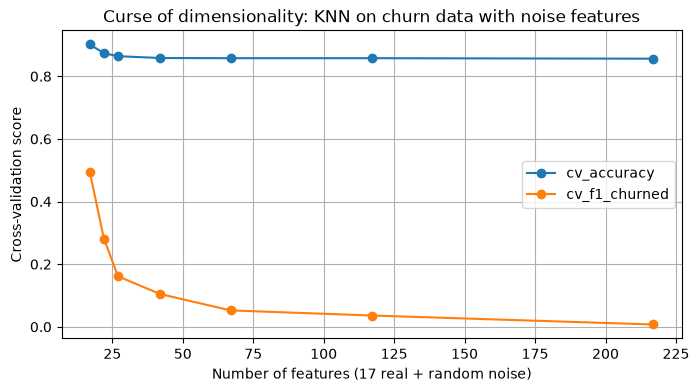

In [20]:
from sklearn.metrics import pairwise_distances

rng = np.random.default_rng(RANDOM_STATE)
dimension_rows = []
for n_noise in [0, 5, 10, 25, 50, 100, 200]:
    X_noisy = np.hstack([X_train.to_numpy(), rng.random((len(X_train), n_noise))])
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=best_k))
    scores = cross_validate(model, X_noisy, y_train, cv=cv, scoring=['accuracy', 'f1'])

    distances = pairwise_distances(MinMaxScaler().fit_transform(X_noisy)[:500])
    np.fill_diagonal(distances, np.nan)
    dimension_rows.append({
        'n_features': X_noisy.shape[1],
        'cv_accuracy': scores['test_accuracy'].mean(),
        'cv_f1_churned': scores['test_f1'].mean(),
        'nearest / farthest distance': np.nanmean(np.nanmin(distances, axis=1) / np.nanmax(distances, axis=1)),
    })

dimension_results = pd.DataFrame(dimension_rows).set_index('n_features')
display(dimension_results.round(4))

dimension_results[['cv_accuracy', 'cv_f1_churned']].plot(marker='o', figsize=(8, 4), grid=True)
plt.xlabel('Number of features (17 real + random noise)')
plt.ylabel('Cross-validation score')
plt.title('Curse of dimensionality: KNN on churn data with noise features')
plt.show()

Вывод: к 17 признакам churn я добавлял от 5 до 200 колонок случайного шума и оценивал KNN (K = 9) кросс-валидацией на обучающей выборке. Accuracy упала с 0.9016 до 0.8563, а F1 по ушедшим с 0.495 до 0.007, то есть при 217 признаках модель почти перестала находить ушедших и по accuracy опустилась до уровня ответа «всегда остался» (0.858 в задании 8). Это проклятие размерности: каждая шумовая колонка добавляет к квадрату расстояния случайную величину, и при сотне таких колонок она заглушает настоящие признаки. Я также посчитал отношение расстояния до ближайшего соседа к расстоянию до самой дальней точки, и оно выросло с 0.18 до 0.79, значит, точки становятся почти равноудалёнными. Поэтому для KNN важно убирать лишние признаки (задание 12).

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

In [21]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
# Ваш код регрессии

,train_mse,cv_mse,test_mse
k,,,
1,0.0000,0.1865,0.9808
2,0.0364,0.1504,0.7768
3,0.0541,0.1425,0.8168
5,0.0698,0.1533,0.5271
10,0.1186,0.2155,0.5701
20,0.2354,0.3656,0.7721
50,0.6427,0.8781,1.3117
100,1.2892,1.7026,2.0291
300,4.0646,5.2452,5.0886


Baseline MSE (always predict the mean): 86.3919
Best K by cross-validation MSE: 3, its test MSE: 0.8168
Training range: minutes 2.6-351.5, calls 34-165. Largest test errors:


,total_day_minutes,total_day_calls,total_day_charge,squared_error
1397,0.0,0,0.00,435.835211
1345,0.0,0,0.00,435.835211
1052,12.5,67,2.13,21.560544


Same K with total_day_minutes only: test MSE 0.0052


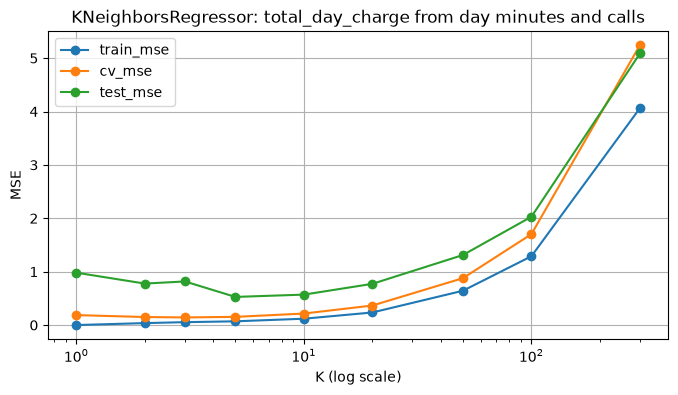

In [22]:
from sklearn.model_selection import KFold

reg_features = ['total_day_minutes', 'total_day_calls']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    data[reg_features], data['total_day_charge'], test_size=0.25, random_state=RANDOM_STATE
)
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

reg_rows = []
for k in [1, 2, 3, 5, 10, 20, 50, 100, 300]:
    model = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=k))
    cv_mse = -cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring='neg_mean_squared_error').mean()
    model.fit(X_reg_train, y_reg_train)
    reg_rows.append({
        'k': k,
        'train_mse': mean_squared_error(y_reg_train, model.predict(X_reg_train)),
        'cv_mse': cv_mse,
        'test_mse': mean_squared_error(y_reg_test, model.predict(X_reg_test)),
    })

reg_results = pd.DataFrame(reg_rows).set_index('k')
display(reg_results.round(4))

best_reg_k = reg_results['cv_mse'].idxmin()
print(f"Baseline MSE (always predict the mean): {mean_squared_error(y_reg_test, np.full(len(y_reg_test), y_reg_train.mean())):.4f}")
print(f"Best K by cross-validation MSE: {best_reg_k}, its test MSE: {reg_results.loc[best_reg_k, 'test_mse']:.4f}")

best_model = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=best_reg_k)).fit(X_reg_train, y_reg_train)
squared_errors = (y_reg_test - best_model.predict(X_reg_test)) ** 2
print(f"Training range: minutes {X_reg_train['total_day_minutes'].min()}-{X_reg_train['total_day_minutes'].max()}, "
      f"calls {X_reg_train['total_day_calls'].min()}-{X_reg_train['total_day_calls'].max()}. Largest test errors:")
display(X_reg_test.assign(total_day_charge=y_reg_test, squared_error=squared_errors).nlargest(3, 'squared_error'))

minutes_only = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=best_reg_k))
minutes_only.fit(X_reg_train[['total_day_minutes']], y_reg_train)
print(f"Same K with total_day_minutes only: test MSE "
      f"{mean_squared_error(y_reg_test, minutes_only.predict(X_reg_test[['total_day_minutes']])):.4f}")

reg_results.plot(marker='o', logx=True, figsize=(8, 4), grid=True)
plt.xlabel('K (log scale)')
plt.ylabel('MSE')
plt.title('KNeighborsRegressor: total_day_charge from day minutes and calls')
plt.show()

Вывод: я предсказывал total_day_charge (в условии он назван total_day_charges) по total_day_minutes и total_day_calls с помощью KNeighborsRegressor, а K выбирал по MSE на кросс-валидации, чтобы не подгонять его под тестовую выборку. При K = 1 MSE на обучающей выборке равна 0, потому что модель запоминает данные (задание 5), а лучший результат на кросс-валидации дал K = 3 с MSE 0.1425. При больших K ошибка растёт до 5.2452 при K = 300, так как модель усредняет клиентов с очень разными минутами, но это всё равно намного лучше ответа средним значением (MSE 86.3919). На тестовой выборке MSE при K = 3 равна 0.8168, и почти вся она из-за двух клиентов с 0 минут и 0 звонков: в обучающей выборке таких нет (минимум 2.6 минуты и 34 звонка), а KNN не умеет экстраполировать, поэтому квадрат ошибки у каждого из них около 436. Кроме того, признак звонков, скорее всего, только мешает, потому что начисление зависит от минут, и с одними минутами MSE на тесте равна 0.0052. От классификации регрессия отличается тем, что ответом становится среднее значение соседей, а не голосование.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest

# Настройка Pipeline и GridSearchCV

In [24]:
from sklearn.metrics import f1_score

pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest()),
    ('knn', KNeighborsClassifier()),
])
param_grid = {
    'select__k': [5, 10, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring={'f1': 'f1', 'accuracy': 'accuracy'}, refit='f1')
grid.fit(X_train, y_train)
y_pred = grid.predict(X_test)

search_results = pd.DataFrame(grid.cv_results_)

print(f"Combinations tested: {len(search_results)} x {cv.get_n_splits()} folds")
print(f"Best hyperparameters (by CV F1): {grid.best_params_}")
print(f"Best mean CV F1: {grid.best_score_:.4f}")
print("For comparison, best combinations by CV accuracy:")
comparison_columns = ['param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p', 'param_select__k',
                      'mean_test_accuracy', 'mean_test_f1']
display(search_results.loc[search_results['rank_test_accuracy'] == 1, comparison_columns].round(4))
print(f"Selected features: {list(grid.best_estimator_[:-1].get_feature_names_out())}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test F1 (churned): {f1_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=['stayed', 'churned'], digits=3))

Combinations tested: 60 x 5 folds
Best hyperparameters (by CV F1): {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 10}
Best mean CV F1: 0.6447
For comparison, best combinations by CV accuracy:


,param_knn__n_neighbors,param_knn__weights,param_knn__p,param_select__k,mean_test_accuracy,mean_test_f1
49,11,uniform,1,10,0.9181,0.6237
52,11,distance,1,10,0.9181,0.6327


Selected features: ['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'total_intl_minutes', 'total_intl_charge', 'number_customer_service_calls']
Test accuracy: 0.9088
Test F1 (churned): 0.5986
              precision    recall  f1-score   support

      stayed      0.920     0.979     0.949      1073
     churned      0.794     0.480     0.599       177

    accuracy                          0.909      1250
   macro avg      0.857     0.730     0.774      1250
weighted avg      0.902     0.909     0.899      1250



Вывод: я собрал pipeline из MinMaxScaler, SelectKBest и KNeighborsClassifier и через GridSearchCV перебрал 60 комбинаций (K из {3, 5, 7, 9, 11}, uniform или distance, p = 1 или p = 2, а также 5, 10 или все признаки) на 5 фолдах обучающей выборки. Лучшими по F1 оказались K = 5, p = 1, weights = uniform и 10 признаков со средним F1 на кросс-валидации 0.6447. Подбирал я по F1, а не по accuracy, потому что важно находить ушедших клиентов (задание 8), а по accuracy лучшими были бы комбинации с K = 11, у которых F1 ниже (0.6237 и 0.6327). На тестовой выборке модель получила accuracy 0.9088 и F1 0.5986, а recall ушедших вырос до 0.480 против 0.356 в задании 8. Вероятно, помог и отбор признаков, так как SelectKBest убрал account_length, счётчики звонков и ночные минуты, которые слабо связаны с оттоком, но отдельно влияние каждого параметра я не проверял.